# Assignment 5 — ANOVA and Simple Linear Regression

## Group members

- Bibek Chaudhary (344326)
- Samo Susa (343876)
- Sneha Koirala (345788)
- Tomas Psotka (343207)

## Table of contents

1. [Imports and display settings](#imports)
2. [Part 1 — Composite strength across curing methods](#part-1)
3. [Part 2 — Diagnostics, post-hoc comparisons, and magnitude](#part-2)
4. [Part 3 — Pump flow and energy use](#part-3)
5. [Part 4 — Regression diagnostics and prediction](#part-4)
6. [Part 5 — AI-use and conclusion](#part-5)

Parts 1–2 are completed, Parts 3–4 contain placeholders, and Part 5 is a
provisional draft. Both datasets are loaded below. Update Part 5 after
completing the regression analysis and the group's review.


<a id="imports"></a>

## Imports and display settings

We use the ANOVA methods from Sessions 9–10. Tests use $\alpha=0.05$ and
confidence intervals have 95% confidence. Statsmodels fits the one-way model
and supplies classical ANOVA, Welch ANOVA and Tukey HSD; SciPy independently
checks the classical $F$ test and constructs the normal QQ-plot.

A 95% confidence procedure covers its population parameter in approximately
95% of repeated comparable samples when its assumptions hold. Tukey's
simultaneous intervals account for the whole family of six pairwise mean
differences, rather than providing six separate unadjusted intervals.


In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

alpha = 0.05
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": False})


In [2]:
# Run from either the repository root or the notebook folder.
filenames = {
    "Composite strength": "assignment05_composite_strength.csv",
    "Pump energy": "assignment05_pump_energy.csv",
}
data_dir = next(
    (folder for folder in [Path("data"), Path("../data")]
     if all((folder / filename).is_file() for filename in filenames.values())),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Run from the repository root or Assignment5 folder, with both CSVs in data/."
    )

datasets = {name: pd.read_csv(data_dir / filename)
            for name, filename in filenames.items()}
strength = datasets["Composite strength"]
pump = datasets["Pump energy"]

quality_rows = []
for name, frame in datasets.items():
    quality_rows.append({
        "Dataset": name, "Rows": len(frame), "Columns": frame.shape[1],
        "Missing values": int(frame.isna().sum().sum()),
        "Duplicate IDs": int(frame.iloc[:, 0].duplicated().sum()),
    })
    print(f"{name}: {filenames[name]}")
    display(frame.head())

display(pd.DataFrame(quality_rows).set_index("Dataset"))

assert all(not frame.isna().any().any() for frame in datasets.values())
assert all(frame.iloc[:, 0].is_unique for frame in datasets.values())
assert pd.api.types.is_numeric_dtype(strength["strength_mpa"])
assert np.isfinite(strength["strength_mpa"]).all()


Composite strength: assignment05_composite_strength.csv


,specimen_id,curing_method,strength_mpa
0,1,ambient,53.0900
1,2,ambient,48.9100
2,3,ambient,55.1100
3,4,ambient,54.5300
4,5,ambient,57.0500


Pump energy: assignment05_pump_energy.csv


,run_id,flow_l_min,energy_kwh
0,1,22.7000,18.1100
1,2,22.9300,13.5340
2,3,23.4200,15.3000
3,4,24.3500,17.6770
4,5,25.1300,18.4200


,Rows,Columns,Missing values,Duplicate IDs
Dataset,,,,
Composite strength,96,3,0,0
Pump energy,55,3,0,0


**Data checks:** The files contain 96 composite specimens and 55 pump runs.
Neither file has missing entries or duplicated IDs. These checks establish
file consistency; they do not establish independence, random assignment or
representative sampling. The original CSV files remain unchanged.


<a id="part-1"></a>

## Part 1 — Composite strength across curing methods

### a. Identify the population, observational unit, response, factor and factor levels. Explain what additional design information would be needed for a causal claim.


**Answer (a):** The engineering question is whether the population mean
composite strength differs between the four curing methods.

| Item | Definition in this study |
|---|---|
| Target population | Comparable composite specimens produced and strength-tested under the material, production and testing conditions represented by this study, for each curing method. |
| Sample | The 96 specimens in the supplied file. |
| Observational unit | One composite specimen; one row records its method and measured strength. |
| Response | `strength_mpa`: quantitative, continuous strength measured in MPa. |
| Factor | `curing_method`: a categorical, nominal explanatory variable. |
| Factor levels | `ambient`, `thermal`, `uv` and `hybrid`. |
| Identifier | `specimen_id` labels specimens; its numerical values are not strength measurements. |

Let $\mu_i$ denote the population mean strength, in MPa, for method $i$ under
comparable conditions. The supplied description calls the specimens
independent, but does not explain how the methods were allocated.

For a **causal claim**, we would need evidence of random assignment of
comparable specimens to methods, a consistent treatment protocol, and control
of material composition, specimen geometry, curing duration and testing
conditions. We would also ask whether material batches or test days were
shared, and whether randomisation or blocking addressed those effects.
Without these details, method differences could also reflect other production
differences. Random assignment supports causal interpretation; representative
sampling or other evidence of comparability supports generalisation to a
wider population. One does not establish the other.


### b. Report group sample sizes, means and sample standard deviations. Create side-by-side boxplots and describe between-group differences and within-group variation.

For each method $i$, calculate the sample size $n_i$, sample mean $\bar y_i$
and sample standard deviation $s_i$:

$$
\bar y_i=\frac{1}{n_i}\sum_{j=1}^{n_i}y_{ij},\qquad
s_i=\sqrt{\frac{\sum_{j=1}^{n_i}(y_{ij}-\bar y_i)^2}{n_i-1}}.
$$

The sample SD uses $n_i-1$ and describes variation among individual specimens
within a method. It is different from the standard error of a group mean.


In [3]:
method_order = ["ambient", "thermal", "uv", "hybrid"]
group_values = [
    strength.loc[strength["curing_method"] == method, "strength_mpa"]
    for method in method_order
]
group_summary = strength.groupby("curing_method")["strength_mpa"].agg(
    n="count", mean_mpa="mean",
    sample_sd_mpa=lambda values: values.std(ddof=1),
).reindex(method_order)
display(group_summary)

print(f"Total number of specimens: {group_summary['n'].sum()}")
print(f"Overall sample mean: {strength['strength_mpa'].mean():.4f} MPa")


,n,mean_mpa,sample_sd_mpa
curing_method,,,
ambient,24,52.1783,5.5494
thermal,24,55.8183,4.0913
uv,24,55.4167,3.4407
hybrid,24,63.5721,6.1955


Total number of specimens: 96
Overall sample mean: 56.7464 MPa


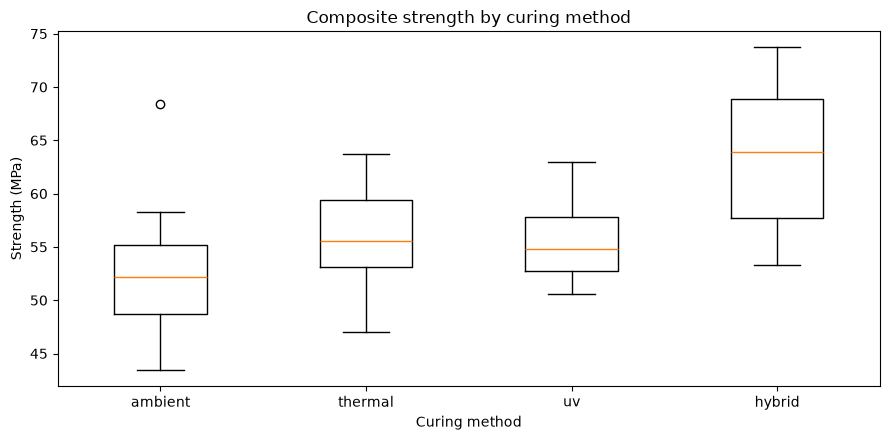

In [4]:
fig, ax = plt.subplots()
ax.boxplot(group_values, tick_labels=method_order)
ax.set(
    title="Composite strength by curing method",
    xlabel="Curing method", ylabel="Strength (MPa)",
)
plt.tight_layout()
plt.show()


**Interpretation:** Each method has 24 specimens, so the design is balanced.
Mean strength is 52.1783 MPa for ambient, 55.8183 MPa for thermal,
55.4167 MPa for UV and 63.5721 MPa for hybrid. Hybrid has the highest sample
mean: 11.3938 MPa above ambient, 7.7538 MPa above thermal and 8.1554 MPa
above UV. Thermal and UV differ by only 0.4017 MPa in the sample.

The boxplots show the higher centre of the hybrid group and considerable
overlap among ambient, thermal and UV. Within-group variation remains
substantial: sample SDs are 5.5494, 4.0913, 3.4407 and 6.1955 MPa for
ambient, thermal, UV and hybrid, respectively. Hybrid has the widest SD and
UV the narrowest. The high ambient observation at 68.41 MPa is flagged by
the boxplot; we investigate it in Part 2 rather than delete it automatically.

These are descriptive differences. Boxplot overlap alone does not test
population mean differences; uncertainty and simultaneous pairwise
comparisons are assessed below.


### c. State the one-way ANOVA hypotheses. Explain why a collection of unadjusted pairwise t-tests is a poor default.

**Answer (c):** With $\alpha=0.05$, the global hypotheses are

$$
H_0:\mu_{\mathrm{ambient}}=\mu_{\mathrm{thermal}}
=\mu_{\mathrm{uv}}=\mu_{\mathrm{hybrid}},
$$

$$H_1:\text{not all four population means are equal}.$$

The alternative means that at least one pair of means differs; it does not
require every pair to differ. The ANOVA test answers this global question
without identifying the particular pairs.

Four methods produce $\binom{4}{2}=6$ pairwise comparisons. Running all six
unadjusted tests at 5% does not control the probability of at least one false
positive across the family at 5%. For six independent tests, that probability
would be $1-(1-0.05)^6\approx26.5\%$. Here the tests share groups and are
dependent, so 26.5% is an illustration, not the exact family-wise error rate.
We use ANOVA for the global question and, if the classical model is credible
and significant, Tukey HSD for simultaneous pairwise inference in Part 2.


### d. Fit the classical one-way model and produce an ANOVA table. Report sums of squares, degrees of freedom, mean squares, F and p, and explain the F ratio.

The classical model separates each response into a group mean and an error:

$$Y_{ij}=\mu_i+\varepsilon_{ij},\qquad
\varepsilon_{ij}\overset{\mathrm{ind}}{\sim}N(0,\sigma^2).$$

It assumes independent errors, a common within-group variance and approximately
normal within-group errors for the usual small-sample inference. We fit
`strength_mpa ~ C(curing_method)` so that statsmodels treats curing method as
categorical. Fitted values are the sample means of the corresponding groups.

With $k=4$ methods, $N=96$ specimens and overall mean $\bar y$, the ANOVA
calculations are

$$
SS_{\mathrm{between}}=\sum_{i=1}^{k}n_i(\bar y_i-\bar y)^2,\qquad
SS_{\mathrm{within}}=\sum_{i=1}^{k}\sum_{j=1}^{n_i}(y_{ij}-\bar y_i)^2,
$$

$$
SS_{\mathrm{total}}=\sum_{i,j}(y_{ij}-\bar y)^2
=SS_{\mathrm{between}}+SS_{\mathrm{within}},
$$

$$
MS_{\mathrm{between}}=\frac{SS_{\mathrm{between}}}{k-1},\qquad
MS_{\mathrm{within}}=\frac{SS_{\mathrm{within}}}{N-k},\qquad
F=\frac{MS_{\mathrm{between}}}{MS_{\mathrm{within}}}.
$$


In [5]:
strength_model = ols("strength_mpa ~ C(curing_method)", data=strength).fit()
anova_raw = anova_lm(strength_model, typ=1)

# Calculate the sums of squares directly to check the fitted-model table.
N = len(strength)
k = len(group_summary)
grand_mean = strength["strength_mpa"].mean()
ss_between = (
    group_summary["n"] * (group_summary["mean_mpa"] - grand_mean)**2
).sum()
ss_within = sum(((values - values.mean())**2).sum() for values in group_values)
ss_total = ((strength["strength_mpa"] - grand_mean)**2).sum()

classical_f = float(anova_raw.loc["C(curing_method)", "F"])
classical_p = float(anova_raw.loc["C(curing_method)", "PR(>F)"])
ms_within = ss_within / (N - k)

anova_table = pd.DataFrame({
    "SS (MPa squared)": [ss_between, ss_within, ss_total],
    "df": [k - 1, N - k, N - 1],
    "MS (MPa squared)": [ss_between / (k - 1), ms_within, np.nan],
    "F": [classical_f, np.nan, np.nan],
    "p-value": [classical_p, np.nan, np.nan],
}, index=["Between curing methods", "Within methods (error)", "Total"])
# Use a display copy so small p-values remain visible without extra packages.
anova_display = anova_table.copy()
anova_display["p-value"] = anova_display["p-value"].map(
    lambda value: f"{value:.6e}" if pd.notna(value) else "—"
)
display(anova_display.fillna("—"))

print(f"F({k - 1}, {N - k}) = {classical_f:.4f}")
print(f"Upper-tail p-value: {classical_p:.6e}")
print(f"Pooled within-group SD: {np.sqrt(ms_within):.4f} MPa")

np.testing.assert_allclose(
    [ss_between, ss_within], anova_raw["sum_sq"].to_numpy()
)
np.testing.assert_allclose(ss_total, ss_between + ss_within)
scipy_anova = stats.f_oneway(*group_values)
np.testing.assert_allclose(classical_f, scipy_anova.statistic)
np.testing.assert_allclose(classical_p, scipy_anova.pvalue, rtol=1e-10, atol=0)


,SS (MPa squared),df,MS (MPa squared),F,p-value
Between curing methods,1682.0804,3,560.6935,22.9423,3.554955e-11
Within methods (error),2248.4130,92,24.4393,—,—
Total,3930.4934,95,—,—,—


F(3, 92) = 22.9423
Upper-tail p-value: 3.554955e-11
Pooled within-group SD: 4.9436 MPa


**Interpretation:** The between-method sum of squares is 1682.0804 MPa$^2$
with 3 degrees of freedom, and the within-method sum of squares is
2248.4130 MPa$^2$ with 92 degrees of freedom. They sum to the total
3930.4934 MPa$^2$ with 95 degrees of freedom.

The ratio is

$$F=\frac{560.6935}{24.4393}=22.9423.$$

The numerator measures variation among sample means, weighted by group size
and scaled by its degrees of freedom. The denominator measures specimen
variation around its own group mean. Under $H_0$ and the classical assumptions,
both mean squares estimate the same error variance, so their ratio is
typically around one. Here between-method variation is large relative to
within-method variation. $F$ is dimensionless, whereas SS and MS have units
MPa$^2$; the pooled within-group SD is 4.9436 MPa.

The upper-tail $p$-value is $3.554955\times10^{-11}$ for $F_{3,92}$.
Conditional on equal population means and the model assumptions, this is the
probability of an $F$ statistic at least as large as 22.9423. It is not the
probability that $H_0$ is true. Since $p<0.05$, the classical test rejects
equal population means. Its interpretation remains conditional on the
diagnostics in Part 2, which also provide effect sizes and uncertainty for
specific differences in MPa.


<a id="part-2"></a>

## Part 2 — Diagnostics, post-hoc comparisons, and magnitude

### a. Diagnose independence from the study description and inspect group spreads, residual-versus-fitted and a normal QQ-plot. Explain why the pooled raw response is not the correct normality diagnostic.

**Independence:** The assignment describes independent specimens, with one
response per specimen and no pairing or repeated measurement. We use this
design assumption, but unique IDs and diagnostic plots cannot verify it.
We would request batch membership, production and test dates, method
allocation and information about shared equipment or material. Specimens
sharing a batch or test condition might have correlated errors. IDs are
grouped by method in this file and are not documented as chronological run
order, so an ID plot would not establish time independence.

**Within-group errors:** For specimen $j$ in method $i$, the fitted residual is

$$e_{ij}=y_{ij}-\widehat y_{ij}=y_{ij}-\bar y_i.$$

We compare sample SDs and IQRs, inspect residual spread around zero at each
fitted group mean, and compare ordered residuals with normal quantiles.
The $1.5\times\mathrm{IQR}$ rule flags observations for investigation; it is
not a rule for automatic deletion or a formal test of normality.


In [6]:
spread_rows = []
flagged_specimens = []
for method, values in zip(method_order, group_values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    flags = strength.loc[
        (strength["curing_method"] == method)
        & ((strength["strength_mpa"] < lower_fence)
           | (strength["strength_mpa"] > upper_fence))
    ]
    spread_rows.append({
        "Curing method": method, "Sample SD (MPa)": values.std(ddof=1),
        "Sample variance (MPa squared)": values.var(ddof=1),
        "IQR (MPa)": iqr, "Skewness": values.skew(),
        "IQR flags": len(flags),
    })
    flagged_specimens.append(flags)

spread_table = pd.DataFrame(spread_rows).set_index("Curing method")
display(spread_table)
print("Specimens flagged by the within-group IQR rule:")
display(pd.concat(flagged_specimens, ignore_index=True))

sd_ratio = group_summary["sample_sd_mpa"].max() / group_summary["sample_sd_mpa"].min()
variance_ratio = sd_ratio**2
print(f"Largest / smallest sample SD: {sd_ratio:.4f}")
print(f"Largest / smallest sample variance: {variance_ratio:.4f}")


,Sample SD (MPa),Sample variance (MPa squared),IQR (MPa),Skewness,IQR flags
Curing method,,,,,
ambient,5.5494,30.7959,6.4400,0.7956,1
thermal,4.0913,16.7387,6.3075,-0.0440,0
uv,3.4407,11.8381,5.0625,0.3789,0
hybrid,6.1955,38.3843,11.1550,-0.1073,0


Specimens flagged by the within-group IQR rule:


,specimen_id,curing_method,strength_mpa
0,13,ambient,68.4100


Largest / smallest sample SD: 1.8007
Largest / smallest sample variance: 3.2424


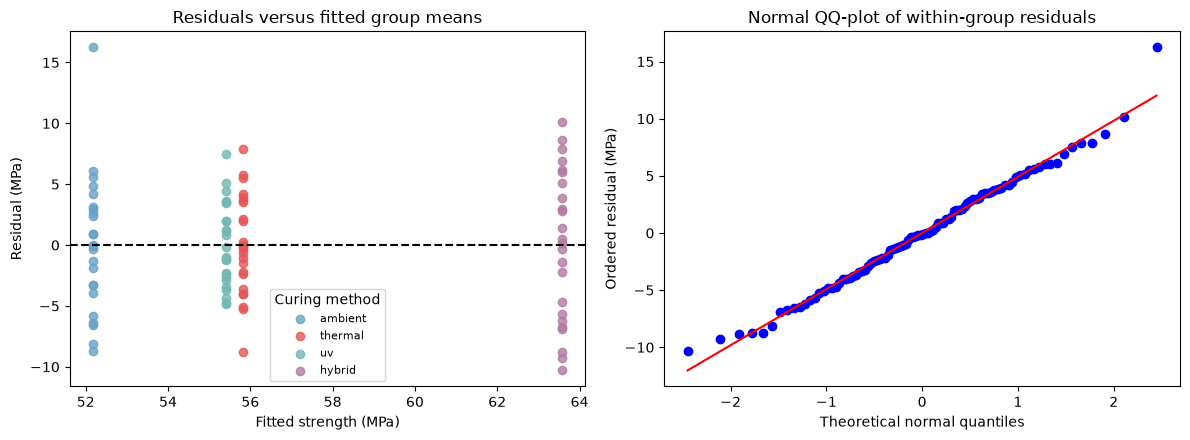

In [7]:
residuals = strength_model.resid
fitted = strength_model.fittedvalues
method_colors = ["#66A2C6", "#E45756", "#72B7B2", "#B279A2"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for method, color in zip(method_order, method_colors):
    mask = strength["curing_method"] == method
    axes[0].scatter(fitted[mask], residuals[mask], color=color, alpha=0.8,
                    label=method)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(
    title="Residuals versus fitted group means",
    xlabel="Fitted strength (MPa)", ylabel="Residual (MPa)",
)
axes[0].legend(title="Curing method", fontsize=8)

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set(
    title="Normal QQ-plot of within-group residuals",
    xlabel="Theoretical normal quantiles", ylabel="Ordered residual (MPa)",
)
plt.tight_layout()
plt.show()


**Diagnostic interpretation:** The sample SDs range from 3.4407 MPa for UV
to 6.1955 MPa for hybrid. The largest/smallest SD ratio is 1.8007, equivalent
to a sample variance ratio of 3.2424. Hybrid also has the widest IQR
(11.1550 MPa), compared with 5.0625–6.4400 MPa for the other groups.
Thus equal variance is an approximation that needs caution.

The residual-versus-fitted plot has four vertical bands because each method
has one fitted mean. Each band's residuals are centred at zero by the fitting
procedure; this is not independent evidence that all assumptions hold.
The bands show the wider hybrid and ambient spreads and the high positive
ambient residual. We should assess these group spreads rather than interpret
the four bands as a continuous regression trend.

The residual QQ-plot is broadly close to a straight line, with some tail
departures, including the largest positive residual. Within-group skewness
is approximately 0.796 for ambient, −0.044 for thermal, 0.379 for UV and
−0.107 for hybrid. There is no strong evidence of severe within-group skewness,
but these samples cannot establish exact normality.

Only **specimen 13**, ambient strength **68.41 MPa**, lies outside its group's
IQR fences. Its residual is $68.41-52.1783=16.2317$ MPa. We would check the
original measurement, units, material batch and treatment record. In the
absence of evidence of a recording or experimental error, it remains in the
analysis. A high value alone is not justification for deletion.

**Why not assess normality of all raw strengths together?** ANOVA assumes
normal errors around each method's own population mean, rather than normality
of a mixture of groups with different means. Pooling raw strengths mixes the
between-method differences into the shape and can make it appear skewed or
multimodal even when within-group errors are normal. Model residuals remove
the fitted group means and target the relevant error distribution. Their
QQ-plot still needs to be read alongside the separate group spreads.


### b. Decide whether the classical common-variance model is credible. Run Welch's one-way ANOVA as a sensitivity analysis and explain why it is not paired automatically with ordinary Tukey HSD.

**Model assessment:** We retain the classical model as a **cautious working
approximation**. All four groups have 24 specimens, and the residual shape
does not show severe departures from normality. A balanced design makes the
classical global test less sensitive to moderate variance differences than
an unbalanced design. Nevertheless, SDs differ by a factor of 1.80, and the
hybrid spread is visibly wider, so a common variance is not established.

We therefore also run **Welch's one-way ANOVA**, testing the same equality
of population means while allowing different population variances. It uses
group-specific variances and approximate denominator degrees of freedom.
It still requires independent observations and reasonably well-behaved
within-group distributions. We do not use a preliminary variance-test
$p$-value as an automatic switch between the models.


In [8]:
welch_result = anova_oneway(
    strength["strength_mpa"], groups=strength["curing_method"],
    use_var="unequal", welch_correction=True,
)
test_comparison = pd.DataFrame([
    {"Method": "Classical one-way ANOVA", "F": classical_f,
     "Numerator df": k - 1, "Denominator df": N - k,
     "p-value": classical_p},
    {"Method": "Welch one-way ANOVA", "F": welch_result.statistic,
     "Numerator df": welch_result.df_num,
     "Denominator df": welch_result.df_denom,
     "p-value": welch_result.pvalue},
]).set_index("Method")
test_display = test_comparison.copy()
test_display["p-value"] = test_display["p-value"].map(lambda value: f"{value:.6e}")
display(test_display)

# This records the diagnostic judgement above; it is not a variance-test result.
classical_credible = True


,F,Numerator df,Denominator df,p-value
Method,,,,
Classical one-way ANOVA,22.9423,3.0000,92.0000,3.554955e-11
Welch one-way ANOVA,15.5674,3.0000,49.9435,2.811103e-07


**Interpretation:** Welch's analysis gives
$F(3,49.9435)=15.5674$ with $p=2.811103\times10^{-7}$.
It also rejects equal population means at 5%. The global conclusion therefore
persists when separate group variances are allowed, although the statistic
and $p$-value change. Agreement does not prove equal variance or independence.
The calculation uses the unequal-variance option documented in
[statsmodels' Welch ANOVA reference](https://www.statsmodels.org/stable/generated/statsmodels.stats.oneway.anova_oneway.html).

**Compatibility with post-hoc inference:** Ordinary Tukey HSD uses a pooled
within-group variance from the classical model. Welch ANOVA allows unequal
variances, so its significant result does not automatically justify ordinary
Tukey intervals. If we rejected the common-variance approximation, we would
need a compatible unequal-variance pairwise procedure instead. Here we report
Tukey as a follow-up to the significant **classical** analysis retained above,
and interpret its intervals conditionally on that approximation. Welch's
global result is a sensitivity check, not a validation of the Tukey intervals.


### c. Calculate eta squared and interpret it as a descriptive fraction of observed squared variation, not causation.

The effect-size summary is

$$\eta^2=\frac{SS_{\mathrm{between}}}{SS_{\mathrm{total}}}.$$

This compares the squared variation among group means with the total squared
variation of the observed specimen strengths around the overall sample mean.


In [9]:
eta_squared = ss_between / ss_total
print(f"Between-method SS: {ss_between:.4f} MPa squared")
print(f"Total SS: {ss_total:.4f} MPa squared")
print(f"Eta squared: {eta_squared:.6f}")
print(f"Descriptive fraction of observed squared variation: {100 * eta_squared:.2f}%")

# In this one-factor model with an intercept, eta squared also equals R squared.
np.testing.assert_allclose(eta_squared, strength_model.rsquared)


Between-method SS: 1682.0804 MPa squared
Total SS: 3930.4934 MPa squared
Eta squared: 0.427957
Descriptive fraction of observed squared variation: 42.80%


**Interpretation:**

$$\eta^2=\frac{1682.0804}{3930.4934}=0.42796\approx42.8\%.$$

Approximately 42.8% of the **observed total squared variation** is represented
by differences among the four sample group means; approximately 57.2% remains
within groups. This is a dimensionless descriptive statistic for this sample.
It does not mean that curing method caused 42.8% of strength variation, that
strength increased by 42.8%, or that the population fraction is known without
uncertainty. The unknown allocation and sampling design limit causal and
population interpretations. Pairwise differences and their intervals below
express magnitude and uncertainty directly in MPa.


### d. If the classical omnibus test is relevant and significant, perform Tukey HSD. Report simultaneous pairwise intervals and adjusted p-values and identify distinguishable methods.

The classical test is significant and its model is retained as a working
approximation in Question (b), so we use **Tukey HSD** for all six mean
differences. For equal group sizes $n=24$, each simultaneous interval is

$$
(\bar y_j-\bar y_i)\ \pm q_{1-\alpha;k,N-k}\sqrt{\frac{MS_{\mathrm{within}}}{n}},
$$

where $q$ is a studentized-range critical value. The common variance is
estimated from all four groups. Tukey adjusts the comparisons for a family-wise
error rate of 5% under the classical model.

**Comparison direction:** Every table row reports **Group 2 minus Group 1**,
in MPa. Positive differences favour Group 2. An interval excluding zero and
an adjusted $p<0.05$ identify a distinguishable pair at this family-wise level.


In [10]:
if classical_credible and classical_p < alpha:
    # The default is ordinary, pooled-variance Tukey HSD.
    tukey_result = pairwise_tukeyhsd(
        endog=strength["strength_mpa"],
        groups=strength["curing_method"], alpha=alpha,
    )
    pairs = list(combinations(tukey_result.groupsunique, 2))
    tukey_table = pd.DataFrame({
        "Group 1": [pair[0] for pair in pairs],
        "Group 2": [pair[1] for pair in pairs],
        "Difference (MPa)": tukey_result.meandiffs,
        "95% lower (MPa)": tukey_result.confint[:, 0],
        "95% upper (MPa)": tukey_result.confint[:, 1],
        "Adjusted p-value": tukey_result.pvalues,
        "Reject equal means": tukey_result.reject,
    })
    tukey_display = tukey_table.copy()
    tukey_display["Adjusted p-value"] = tukey_display["Adjusted p-value"].map(
        lambda value: f"{value:.6e}"
    )
    display(tukey_display)

    # Check the comparison direction and the balanced-design interval formula.
    direct_differences = [
        group_summary.loc[group2, "mean_mpa"]
        - group_summary.loc[group1, "mean_mpa"]
        for group1, group2 in pairs
    ]
    np.testing.assert_allclose(tukey_result.meandiffs, direct_differences)
    tukey_margin = stats.studentized_range.ppf(1 - alpha, k, N - k) * np.sqrt(
        ms_within / group_summary["n"].iloc[0]
    )
    np.testing.assert_allclose(
        tukey_result.confint,
        np.column_stack((np.array(direct_differences) - tukey_margin,
                         np.array(direct_differences) + tukey_margin)),
    )
else:
    print("Ordinary Tukey HSD is not justified by the selected omnibus analysis.")


,Group 1,Group 2,Difference (MPa),95% lower (MPa),95% upper (MPa),Adjusted p-value,Reject equal means
0,ambient,hybrid,11.3937,7.6596,15.1279,2.333034e-11,True
1,ambient,thermal,3.6400,-0.0942,7.3742,5.887157e-02,False
2,ambient,uv,3.2383,-0.4958,6.9725,1.128722e-01,False
3,hybrid,thermal,-7.7538,-11.4879,-4.0196,2.668966e-06,True
4,hybrid,uv,-8.1554,-11.8896,-4.4213,8.001018e-07,True
5,thermal,uv,-0.4017,-4.1358,3.3325,9.921696e-01,False


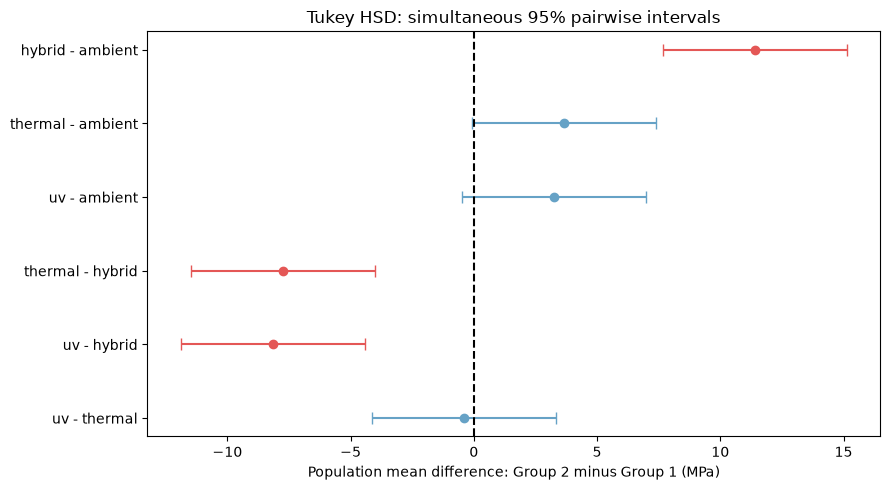

In [11]:
if classical_credible and classical_p < alpha:
    fig, ax = plt.subplots(figsize=(9, 5))
    for row_number, row in tukey_table.iterrows():
        difference = row["Difference (MPa)"]
        color = "#E45756" if row["Reject equal means"] else "#66A2C6"
        ax.errorbar(
            difference, row_number,
            xerr=[[difference - row["95% lower (MPa)"]],
                  [row["95% upper (MPa)"] - difference]],
            fmt="o", color=color, capsize=4,
        )
    ax.axvline(0, color="black", linestyle="--")
    ax.set_yticks(range(len(tukey_table)))
    ax.set_yticklabels([
        f"{row['Group 2']} - {row['Group 1']}"
        for _, row in tukey_table.iterrows()
    ])
    ax.invert_yaxis()
    ax.set(
        title="Tukey HSD: simultaneous 95% pairwise intervals",
        xlabel="Population mean difference: Group 2 minus Group 1 (MPa)",
    )
    plt.tight_layout()
    plt.show()


**Interpretation:** Hybrid is distinguishable from each of the other three
methods. Rewriting those comparisons as **hybrid minus the other method**
gives the following positive mean differences:

| Comparison | Estimated difference (MPa) | Simultaneous 95% interval (MPa) | Adjusted p-value |
|---|---:|---:|---:|
| Hybrid − ambient | 11.3938 | [7.6596, 15.1279] | $2.333034\times10^{-11}$ |
| Hybrid − thermal | 7.7538 | [4.0196, 11.4879] | $2.668966\times10^{-6}$ |
| Hybrid − UV | 8.1554 | [4.4213, 11.8896] | $8.001018\times10^{-7}$ |

The intervals for thermal minus ambient, UV minus ambient, and UV minus
thermal contain zero, with adjusted $p$-values of 0.0589, 0.1129 and 0.9922,
respectively. We do not find sufficient evidence to distinguish these pairs
at the 5% family-wise level. This **does not prove equal population means**:
for example, the thermal-minus-ambient interval is [−0.0942, 7.3742] MPa,
which still permits an appreciable positive difference. Demonstrating
practical equivalence would require a defined equivalence margin and an
appropriate analysis.

Under the classical assumptions, the simultaneous interval procedure covers
all six true pairwise differences together in 95% of repeated comparable
studies. These are intervals for population **mean differences**, not ranges
for individual specimens. Scientific notation preserves the small adjusted
$p$-values rather than displaying them as zero. The implementation is described
in [statsmodels' Tukey HSD reference](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html).
The unequal group spreads make the pooled-variance intervals approximate;
the significant Welch test supports only the global conclusion.


### e. Write a recommendation in MPa that distinguishes the global question, specific pairwise differences, practical importance and design limitations.

**Recommendation:** Hybrid is the strongest candidate for further engineering
evaluation. Its sample mean is **63.57 MPa**, compared with 52.18 MPa for
ambient, 55.82 MPa for thermal and 55.42 MPa for UV.

**Global evidence:** Classical ANOVA rejects equality of all four population
means, $F(3,92)=22.94$, $p=3.55\times10^{-11}$. Welch's sensitivity analysis
also rejects equal means, $p=2.81\times10^{-7}$. This establishes evidence of
some mean difference under the respective assumptions; the global test alone
does not identify the best method or show that every pair differs.

**Specific differences and uncertainty:** Under the classical working model,
hybrid's estimated mean advantage is **11.39 MPa** over ambient (simultaneous
95% interval **7.66–15.13 MPa**), **7.75 MPa** over thermal (**4.02–11.49 MPa**)
and **8.16 MPa** over UV (**4.42–11.89 MPa**). Tukey distinguishes hybrid from
each alternative, while the other three pairwise comparisons remain
inconclusive. The descriptive $\eta^2$ is 0.428; it is not a causal percentage.

**Practical importance:** No minimum useful gain in MPa or strength requirement
is supplied. We would compare these intervals with a pre-specified engineering
threshold, curing time, energy demand, cost and process feasibility before
adoption. For example, whether the possible 4.02–11.49 MPa mean advantage
over thermal warrants hybrid depends on the application's requirements.
Hybrid also has a sample SD of **6.20 MPa**, so a higher mean does not guarantee
that every hybrid specimen meets a required minimum strength. These intervals
describe mean advantages, not individual-specimen reliability.

**Diagnostic and design limits:** The residual QQ-plot is broadly compatible
with normal errors, but group SDs range from 3.44 to 6.20 MPa and there is a
high ambient observation worth checking. The equal sample sizes support
cautious classical analysis; Welch confirms the global result without
establishing the accuracy of pooled Tukey intervals. Independence is stated
in the brief but cannot be established from this CSV. We would verify the
allocation, material batches, testing conditions and sampling process, then
confirm performance in a controlled, appropriately randomised study before
making a causal or wider production claim.


<a id="part-3"></a>

## Part 3 — Pump flow and energy use

**Status: placeholders — analysis to be completed.**

Use `assignment05_pump_energy.csv`, already loaded as `pump`. The response is
energy use $Y$ and the predictor is flow rate $x$, with the model

$$Y=\beta_0+\beta_1x+\varepsilon.$$


### a. Identify the population, observational unit, response, predictor and observed predictor range. Create a scatterplot and assess linearity before fitting.

**To complete:** Define the target population and one benchmark run. State the response and predictor with their units, calculate the minimum and maximum observed flow rates, and inspect the scatterplot before choosing a linear conditional-mean model.


In [ ]:
# TODO: Describe the variables, report the observed flow-rate range and plot energy against flow.


**Interpretation:** To be completed. Describe the direction, shape, variation and any unusual observations in the scatterplot.


### b. Fit an intercept model with statsmodels. Report and interpret $\hat\beta_0$, $\hat\beta_1$, residual standard deviation, Pearson correlation $r$ and $R^2$.

**To complete:** Fit energy use against flow rate with an intercept. Report the intercept (kWh), slope (kWh per L/min), residual SD (kWh), Pearson correlation and coefficient of determination. Discuss whether the intercept has a useful engineering interpretation given the observed flow-rate range.


In [ ]:
# TODO: Fit the simple intercept model and report coefficients, residual SD, Pearson r and R squared.


**Interpretation:** To be completed. Interpret the slope, residual variation and fit in context, including the meaning of the intercept.


### c. Verify that $R^2=r^2$ for this simple intercept model. Explain what correlation and $R^2$ measure and what they do not establish.

**To complete:** Compare the fitted model coefficient of determination with the squared Pearson correlation. Explain the strength and direction measured by correlation and the observed squared variation summarised by the model fit. State the limits of these summaries.


In [ ]:
# TODO: Verify R squared equals r squared for the fitted simple model with an intercept.


**Interpretation:** To be completed. Explain why these summaries do not establish causation or validate all model assumptions.


### d. Test $H_0:\beta_1=0$ against $H_1:\beta_1\ne0$ and report the slope estimate, standard error, 95% interval, $t$, degrees of freedom and $p$-value.

**To complete:** State the population slope parameter and use a two-sided test at $\alpha=0.05$. Report the estimate and uncertainty in kWh per L/min, the test statistic and residual degrees of freedom, and the decision. Interpret the result as an association under the model assumptions.


In [ ]:
# TODO: Report the two-sided slope test and its matching 95% confidence interval.


**Interpretation:** To be completed. Give a contextual conclusion about association and separate statistical from practical significance.


<a id="part-4"></a>

## Part 4 — Regression diagnostics and prediction

**Status: placeholders — analysis to be completed.**

Continue with the pump model fitted in Part 3. Complete these diagnostics
before relying on its coefficient inference or predictions.


### a. Create residual-versus-fitted, residual-versus-run-order and normal QQ-plots. Discuss assumptions and the limits of the diagnostics.

**To complete:** Assess linearity, constant residual spread, unusual observations and the normal-error approximation. Check how actual run order was recorded before using an ID as chronology. Explain what the plots cannot establish about independence, sampling or operating conditions.


In [ ]:
# TODO: Check the run-order information and create the three regression residual diagnostic plots.


**Interpretation:** To be completed. Describe the evidence for each assumption and the design information still needed.


### b. Calculate leverage and Cook's distance. Identify and investigate the most influential run without deleting it automatically.

**To complete:** Report leverage and Cook's distance, identify the run with the largest Cook's distance, and inspect its measurements and residual. Specify the operational information needed to investigate it, such as sensor accuracy, pump settings, maintenance, start-up conditions and data-entry records.


In [ ]:
# TODO: Calculate leverage and Cook's distance, then inspect the most influential run.


**Interpretation:** To be completed. Distinguish an influential observation from a confirmed error and justify how it is handled.


### c. At $x_0=70$ L/min, report fitted mean energy, a 95% confidence interval for mean energy and a 95% prediction interval for one new run.

**To complete:** Use the fitted model to estimate energy at 70 L/min. Label all estimates and interval endpoints in kWh, identify the population mean versus one new run as the respective targets, and explain why the prediction interval is wider.


In [ ]:
# TODO: Predict at 70 L/min and display the fitted mean, mean confidence interval and new-run prediction interval.


**Interpretation:** To be completed. Explain the two kinds of uncertainty and the assumptions needed for a new comparable run.


### d. Explain why using the fitted line at 10 or 120 L/min would be extrapolation. State what evidence would be needed to extend the relationship.

**To complete:** Compare 10 and 120 L/min with the observed flow-rate range from Part 3. Discuss the additional operating data and engineering evidence needed before applying the relationship beyond that range.


In [ ]:
# TODO: Compare 10 and 120 L/min with the observed predictor range; no extrapolated prediction is required.


**Interpretation:** To be completed. Explain why an observed linear relationship need not persist outside the measured operating range.


### e. Give a practical conclusion including slope, uncertainty, residual variation, $R^2$, prediction uncertainty and study-design limitations.

**To complete:** Combine the slope estimate and its interval (kWh per L/min), residual SD (kWh), model fit, diagnostic findings and the prediction interval at 70 L/min. Connect them to an operational decision while limiting causal claims and extrapolation.


In [ ]:
# TODO: Collect the verified regression results needed for the practical conclusion.


**Interpretation:** To be completed. Write the recommendation after completing and reviewing Parts 3–4.


<a id="part-5"></a>

## Part 5 — AI-use and conclusion

**Draft status:** This section records assistance and findings so far.
Revise it after completing Parts 3–4 and record the group's own review,
changes and verification before submission.

### AI-use statement

| Tool | What it contributed |
|---|---|
| **OpenAI Codex** | Matched the earlier notebooks' format; drafted the explanations, Python code, diagnostics and interpretations in Parts 1–2; checked calculations and reviewed the saved files; added the Part 3–4 placeholders; drafted this section and updated the README. |

**Changes made during preparation:** The high ambient-strength observation
was retained for investigation rather than removed automatically. The
common-variance assumption was qualified because group spreads differ;
Welch's global test was kept separate from the justification for ordinary
Tukey HSD. Small p-values were displayed in scientific notation, and
interpretations distinguish observed association from causation. These
are changes made during AI-assisted preparation. The group's own changes
or rejected suggestions still need to be recorded after review.

**Verification so far:** The 11 completed code cells were executed
sequentially in the project's Python environment. Direct sums-of-squares
calculations were checked against statsmodels, the classical ANOVA was
checked against SciPy, and Tukey differences and intervals were checked
against direct group-mean differences and the studentized-range formula.
The effect-size calculation was also checked against the fitted one-way
model's coefficient of determination. Saved tables and plots were inspected
during AI-assisted verification. These checks cover Parts 1–2; regression
calculations have not yet been implemented. The group must still review
and understand the methods, assumptions and conclusions, check them against
the course material, and update this statement with its own verification.

### Overall conclusion

*Provisional conclusion: update with the pump-study findings once Parts 3–4
are completed.*

ANOVA and simple linear regression analyse a quantitative response, but the
predictor determines the question. ANOVA compares mean composite strength
among categorical curing methods. Regression will relate mean pump energy
use to quantitative flow rate, estimating the change in kWh per L/min.

In the completed ANOVA, hybrid had the highest sample mean, 63.57 MPa.
Its estimated mean advantage over ambient was 11.39 MPa, with a simultaneous
95% Tukey interval of 7.66–15.13 MPa under the classical working model.
Classical and Welch tests both found evidence of unequal population means.
The descriptive eta squared of 0.428 summarises observed squared variation;
it does not establish a causal contribution.

Residuals assess the error structure in both methods. ANOVA residuals measure
deviations from fitted group means; regression residuals measure deviations
from the fitted line. The ANOVA QQ-plot was broadly linear, but unequal
spreads require caution with pooled-variance intervals. Regression diagnostics
will assess linearity, spread, unusual observations and influence. Mean-response
confidence intervals and new-run prediction intervals answer different questions.

Statistical significance alone does not establish engineering value. Gains
must be compared with strength requirements, energy targets, costs and
operating constraints. Neither method proves causation: independence,
representative sampling, random assignment and controlled conditions determine
how confidently findings can be generalised or attributed to the predictor.
